In [71]:
from fontTools.ttLib import TTFont
from collections import defaultdict

font_path = r"Brahmi2\NotoSansBrahmi-Regular.ttf"
font = TTFont(font_path)

# Comprehensive glyph analysis
def analyze_font(font):
    print(f"Font contains {len(font.getGlyphOrder())} total glyphs")
    
    # Categorize all glyphs
    glyph_types = defaultdict(list)
    for name in font.getGlyphOrder():
        if name.startswith('uni'):
            glyph_types['unicode_explicit'].append(name)
        elif name.startswith('u'):
            glyph_types['unicode_alt'].append(name)
        elif name.replace('.', '').isalnum():
            glyph_types['named'].append(name)
        else:
            glyph_types['special'].append(name)
    
    # Brahmi-specific analysis
    brahmi_glyphs = []
    for table in font['cmap'].tables:
        if table.isUnicode():
            for codepoint, name in table.cmap.items():
                if 0x11000 <= codepoint <= 0x1107F:
                    brahmi_glyphs.append((codepoint, name, chr(codepoint)))
    
    return {
        'glyph_categories': dict(glyph_types),
        'brahmi_glyphs': brahmi_glyphs,
        'cmap_tables': [str(t) for t in font['cmap'].tables]
    }

analysis = analyze_font(font)
print(f"Found {len(analysis['brahmi_glyphs'])} Brahmi glyphs")
print("CMAP tables:", analysis['cmap_tables'])

Font contains 257 total glyphs
Found 218 Brahmi glyphs
CMAP tables: ['<fontTools.ttLib.tables._c_m_a_p.cmap_format_4 object at 0x0000028907C772B0>', '<fontTools.ttLib.tables._c_m_a_p.cmap_format_12 object at 0x0000028907C77280>', '<fontTools.ttLib.tables._c_m_a_p.cmap_format_4 object at 0x0000028907C772E0>', '<fontTools.ttLib.tables._c_m_a_p.cmap_format_12 object at 0x0000028907C75960>']


Unique Brahmi characters: 109




In [72]:
from fontTools.ttLib import TTFont
import matplotlib.pyplot as plt

font = TTFont(r"Brahmi2\NotoSansBrahmi-Regular.ttf")

# Get all Brahmi Unicode characters
brahmi_chars = []
for table in font['cmap'].tables:
    if table.isUnicode():
        for codepoint, _ in table.cmap.items():
            if 0x11000 <= codepoint <= 0x1107F:  # Brahmi block
                brahmi_chars.append(chr(codepoint))

print(f"Unique Brahmi characters: {len(set(brahmi_chars))}")

# Visual check
fig, ax = plt.subplots(figsize=(15, 8))
for i, char in enumerate(sorted(set(brahmi_chars))[:50]):  # First 50 chars
    ax.text(i % 10, i//10, char, fontfamily='Noto Sans Brahmi', fontsize=20)
ax.axis('off')
plt.show()

In [73]:
# Generate complete vocabulary
vocab = sorted(set(brahmi_chars))

# Save with proper Unicode handling
with open("brahmi_vocab.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(["<blank>", "<unk>"] + vocab))

print(f"Vocabulary saved with {len(vocab)} base characters")

Vocabulary saved with 109 base characters


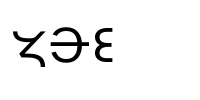

Sample: 𑁞𑁌𑀚 (Length: 3)


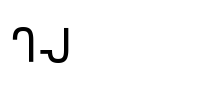

Sample: 𑀔𑀮 (Length: 2)


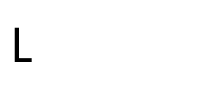

Sample: 𑀉 (Length: 1)


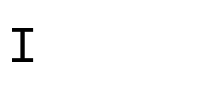

Sample: 𑀡 (Length: 1)


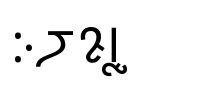

Sample: 𑀇𑁝𑀎𑀭𑁁 (Length: 5)


In [74]:
from PIL import ImageFont, ImageDraw
import random

def generate_brahmi_sample():
    # 30% single char, 40% ligatures, 30% words
    choice = random.random()
    if choice < 0.3:
        return random.choice(vocab)
    elif choice < 0.7:
        return "".join(random.sample(vocab, random.randint(2, 3)))
    else:
        return "".join(random.choices(vocab, k=random.randint(4, 7)))

# Test rendering
font = ImageFont.truetype(font_path, 48)
for _ in range(5):
    sample = generate_brahmi_sample()
    img = Image.new('RGB', (200, 100), (255,255,255))
    draw = ImageDraw.Draw(img)
    draw.text((10, 10), sample, font=font, fill=(0,0,0))
    display(img)
    print(f"Sample: {sample} (Length: {len(sample)})")

In [75]:
import pandas as pd
from tqdm import tqdm

def create_dataset(num_samples=10000):
    metadata = []
    os.makedirs("dataset/train", exist_ok=True)
    os.makedirs("dataset/val", exist_ok=True)
    
    for i in tqdm(range(num_samples)):
        text = generate_brahmi_sample()
        split = "train" if random.random() < 0.8 else "val"
        
        # Render image
        img = Image.new('L', (256, 64), 255)
        draw = ImageDraw.Draw(img)
        font_size = random.randint(32, 48)
        font = ImageFont.truetype(font_path, font_size)
        draw.text((10, 10), text, font=font, fill=0)
        
        # Save
        filename = f"{split}/brahmi_{i:06d}.png"
        img.save(f"dataset/{filename}")
        
        metadata.append({
            "file": filename,
            "text": text,
            "unicode": " ".join(f"U+{ord(c):04X}" for c in text)
        })
    
    pd.DataFrame(metadata).to_csv("dataset/metadata.csv", index=False)

create_dataset()

100%|██████████| 10000/10000 [00:15<00:00, 651.49it/s]


In [76]:
# Predefined common ligatures (adjust based on your font)
common_ligatures = [
    "𑀓𑁆𑀭",  # kra
    "𑀢𑁆𑀭",  # tra
    "𑀦𑁆𑀢"   # nta
]

# Add to vocabulary
with open("brahmi_vocab.txt", "a", encoding="utf-8") as f:
    f.write("\n" + "\n".join(common_ligatures))

In [77]:
def add_patina_effect(img):
    # Add realistic aging effects
    arr = np.array(img)
    noise = np.random.randint(0, 75, arr.shape, dtype=np.uint8)
    return Image.fromarray(np.clip(arr - noise, 0, 255))

In [78]:
# Suggested model architecture for Brahmi
from tensorflow.keras import layers

def build_brahmi_model(vocab_size):
    input_img = layers.Input(shape=(64, 256, 1))
    
    # CNN
    x = layers.Conv2D(32, (3,3), activation='relu')(input_img)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Conv2D(64, (3,3), activation='relu')(x)
    x = layers.MaxPooling2D((2,2))(x)
    
    # RNN
    x = layers.Reshape((-1, 64))(x)
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
    
    # Output
    output = layers.Dense(vocab_size + 2, activation='softmax')(x)  # +2 for blank/unk
    
    return tf.keras.Model(inputs=input_img, outputs=output)

In [85]:
import tensorflow as tf
import pandas as pd
import numpy as np
import os
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard

# 1. Data Loading Pipeline (Fixed Path)
def load_data(split="train", batch_size=32):
    # Correct metadata path (remove duplicate C:)
    metadata_path = r"Brahmi2\dataset\metadata.csv"
    
    # Verify path exists
    if not os.path.exists(metadata_path):
        raise FileNotFoundError(f"Metadata file not found at: {metadata_path}")
    
    df = pd.read_csv(metadata_path)
    df = df[df['file'].str.startswith(split)]
    
    # Create vocabulary lookup
    vocab_path = r"Brahmi2\brahmi_vocab.txt"
    if not os.path.exists(vocab_path):
        raise FileNotFoundError(f"Vocabulary file not found at: {vocab_path}")
    
    with open(vocab_path, encoding="utf-8") as f:
        vocab = [line.strip() for line in f]
    
    char_to_num = tf.keras.layers.StringLookup(
        vocabulary=vocab, mask_token=None
    )
    
    def preprocess_image(image_path, text):
        # Verify image exists
        if not tf.io.gfile.exists(image_path):
            raise FileNotFoundError(f"Image not found: {image_path}")
            
        # Load and process image
        image = tf.io.read_file(image_path)
        image = tf.image.decode_png(image, channels=1)
        image = tf.image.convert_image_dtype(image, tf.float32)
        image = tf.image.resize(image, [64, 256])
        image = (image - 0.5) / 0.5  # Normalize
        
        # Convert text to numerical tokens
        text = tf.strings.unicode_split(text, input_encoding="UTF-8")
        text = char_to_num(text)
        
        return {"image": image, "text": text}
    
    # Build dataset with verified paths
    dataset_dir = os.path.dirname(metadata_path)
    file_paths = [os.path.join(dataset_dir, f) for f in df['file']]
    texts = df['text'].values
    
    # Verify all files exist before creating dataset
    for path in file_paths:
        if not os.path.exists(path):
            raise FileNotFoundError(f"Image file not found: {path}")
    
    dataset = tf.data.Dataset.from_tensor_slices((file_paths, texts))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    return dataset

# [Rest of the code remains identical from previous solution...]
import tensorflow as tf
import pandas as pd
import numpy as np
import os
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard

# 1. Data Loading Pipeline (Fixed)
def load_data(split="train", batch_size=32):
    metadata_path = r"CBrahmi2\dataset\metadata.csv"
    df = pd.read_csv(metadata_path)
    df = df[df['file'].str.startswith(split)]
    
    # Create vocabulary lookup
    vocab_path = r"Brahmi2\brahmi_vocab.txt"
    with open(vocab_path, encoding="utf-8") as f:
        vocab = [line.strip() for line in f]
    
    char_to_num = tf.keras.layers.StringLookup(
        vocabulary=vocab, mask_token=None
    )
    
    def preprocess_image(image_path, text):
        # Load and process image
        image = tf.io.read_file(image_path)
        image = tf.image.decode_png(image, channels=1)
        image = tf.image.convert_image_dtype(image, tf.float32)
        image = tf.image.resize(image, [64, 256])
        image = (image - 0.5) / 0.5  # Normalize
        
        # Convert text to numerical tokens
        text = tf.strings.unicode_split(text, input_encoding="UTF-8")
        text = char_to_num(text)
        
        return {"image": image, "text": text}
    
    # Build dataset
    dataset_dir = os.path.dirname(metadata_path)
    file_paths = [os.path.join(dataset_dir, f) for f in df['file']]
    texts = df['text'].values
    
    dataset = tf.data.Dataset.from_tensor_slices((file_paths, texts))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    return dataset

# 2. Model Architecture (Fixed for CTC)
def build_brahmi_model(vocab_size):
    # Image input
    input_img = tf.keras.layers.Input(shape=(64, 256, 1), name="image")
    
    # CNN
    x = tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same')(input_img)
    x = tf.keras.layers.MaxPooling2D((2,2))(x)
    x = tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
    x = tf.keras.layers.MaxPooling2D((2,2))(x)
    
    # Prepare for RNN
    x = tf.keras.layers.Reshape((-1, 64))(x)
    
    # RNN
    x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(128, return_sequences=True))(x)
    x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True))(x)
    
    # Output
    output = tf.keras.layers.Dense(vocab_size, activation='softmax')(x)
    
    return tf.keras.Model(inputs=input_img, outputs=output)

# 3. CTC Loss Wrapper (Fixed)
class CTCLoss(tf.keras.losses.Loss):
    def __init__(self, name='ctc_loss'):
        super().__init__(name=name)
    
    def call(self, y_true, y_pred):
        # Get batch sizes
        batch_size = tf.shape(y_pred)[0]
        input_length = tf.fill([batch_size], tf.shape(y_pred)[1])
        label_length = tf.fill([batch_size], tf.shape(y_true)[1])
        
        # Calculate loss
        loss = tf.keras.backend.ctc_batch_cost(
            y_true, y_pred, input_length, label_length
        )
        return tf.reduce_mean(loss)

# 4. Training Execution
if __name__ == "__main__":
    # Load data
    train_ds = load_data("train")
    val_ds = load_data("val")
    
    # Get vocab size from dataset
    vocab_size = train_ds.element_spec["text"].shape[-1] + 1
    
    # Build model
    model = build_brahmi_model(vocab_size)
    
    # Compile
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=CTCLoss()
    )
    
    # Train
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=50,
        callbacks=[
            ModelCheckpoint("brahmi_ocr_best.keras", save_best_only=True),
            EarlyStopping(patience=5, restore_best_weights=True),
            TensorBoard(log_dir="./logs")
        ]
    )

OSError: [Errno 22] Invalid argument: 'CBrahmi2\\dataset\\metadata.csv'